# Exploratory Data Analysis

## Credit Card Fraud Analysis

In this notebook, we analyze the Credit Card Fraud dataset to identify patterns and key factors associated with fraudulent transactions.

**Objectives:**

- **Data Cleaning:** Clean the dataset by handling missing or null values appropriately.
- **Feature Analysis:** Identify the core features that are most strongly associated with fraudulent transactions.
- **Data Visualization:** Visualize the data to uncover trends and highlight the primary drivers of fraud.
- **Insights:** Summarize key findings to better understand the underlying causes of credit card fraud.

### Import all necessary library

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

#### Loading the dataset

In [3]:
df = pd.read_csv('./dataset/creditcard.csv')

df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

The dataset contains 284,807 transactions with 31 columns. Most features are anonymized PCA components (V1–V28), along with Time, Amount, and the target variable Class.

In [5]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


No significant outliers are identified at this stage.

In [6]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

No missing values were found in the dataset.

In [7]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [8]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

Fraud transactions account for approximately 0.17% of all observations.

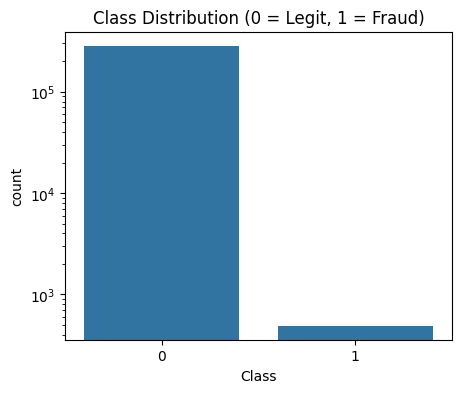

In [9]:
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Class')
plt.title("Class Distribution (0 = Legit, 1 = Fraud)")
plt.yscale('log')
plt.show()

- The target variable is highly imbalanced, with fraud transactions representing only a very small percentage of the dataset.

- Training a machine learning model on this imbalanced dataset could lead to biased predictions, as the model would primarily learn patterns from the majority class while failing to accurately identify the minority class.

- We need to use SMOTE to solve this issue.


#### Amount distribution — fraud vs non-fraud

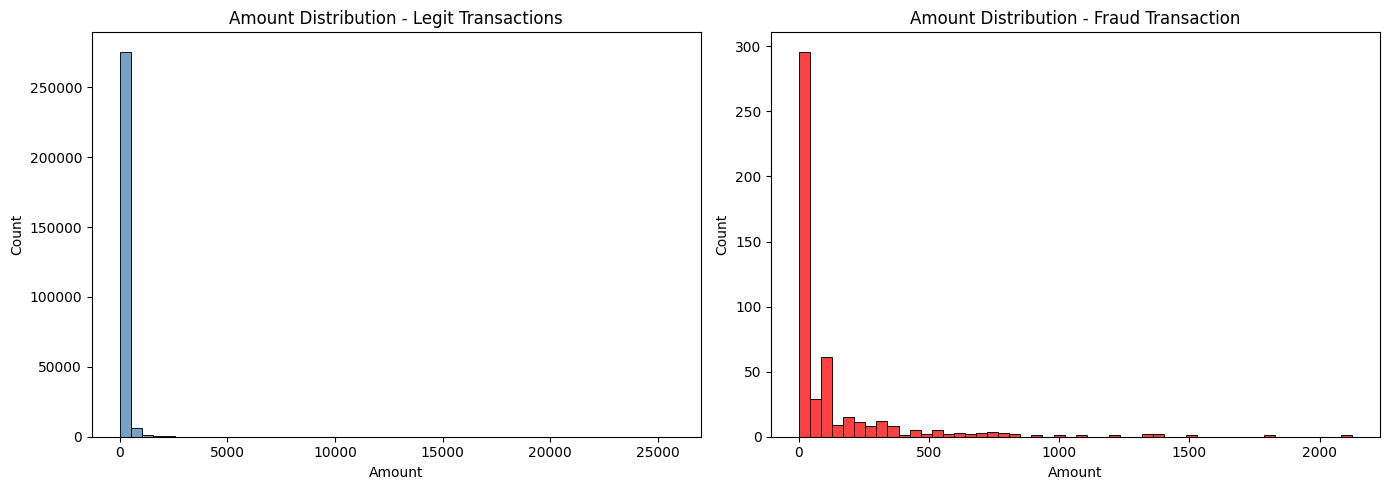

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df[df["Class"]==0], x="Amount", bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Amount Distribution - Legit Transactions")

sns.histplot(data=df[df["Class"]==1], x="Amount", bins=50, ax=axes[1], color="red")
axes[1].set_title("Amount Distribution - Fraud Transaction")

plt.tight_layout()
plt.show()

#### Transaction Amount Distribution Analysis

1. Volume Difference & Imbalance:
  - Legit Transaction: Extremely high total volume (peaking near 280000 counts),
  describing us there are severe imbalance in the dataset.
  - Fraud Transaction: Very low count (peaking under 300 counts),
  highlighting the rare nature of fraud events.

2. Transaction Value Ranges:
  - Legit Transaction: Heavily concentrated near low values ($0 - $1000),
  legitimate amount can extend up to $25,000+, indicating occasional very large transaction.
  - Fraud Transaction: heavily concentrated near lower transaction values, capping around $2100. The majority of fraud cases occur in lower amount ($0 - $250).

3. Distribution Shape:
  - Both distributions are heavily right-skewed, where most transactions involve smaller amounts, followed by a long tail toward higher values.

In [13]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


#### Time distribution — fraud vs non-fraud

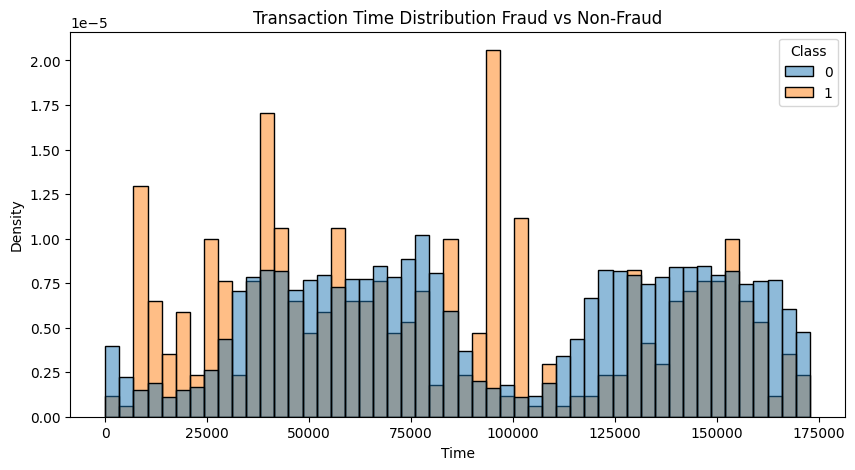

In [16]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='Time', hue='Class', bins=50, stat='density', common_norm=False)
plt.title('Transaction Time Distribution Fraud vs Non-Fraud')
plt.show()

#### Transaction Time Distribution Analysis (Fraud vs Non-Fraud)

1. Non-Fraudulent Activity (Class 0):
  - Displays a clear, periodic cyclical pattern with two distinct peak around $T \approx 100,000$
  - This structure reflects typical human behavior over a two-day period (daytime activity vs. nighttime lulls).

2. Fraudulent Activity (Class 1):
  - Does not follow normal human spending cycles.
  - Features distinct spikes in activity notably around $T \approx 10,000$, $T \approx 40,000$, and a major peak near $T \approx 95,000$ to $100,000$ (during periods when regular transaction density drops).

3. Key Observations:
  - Fraud transaction mostly occur during off-peak hours when regular transaction volumes are low.

#### Correlation heatmap

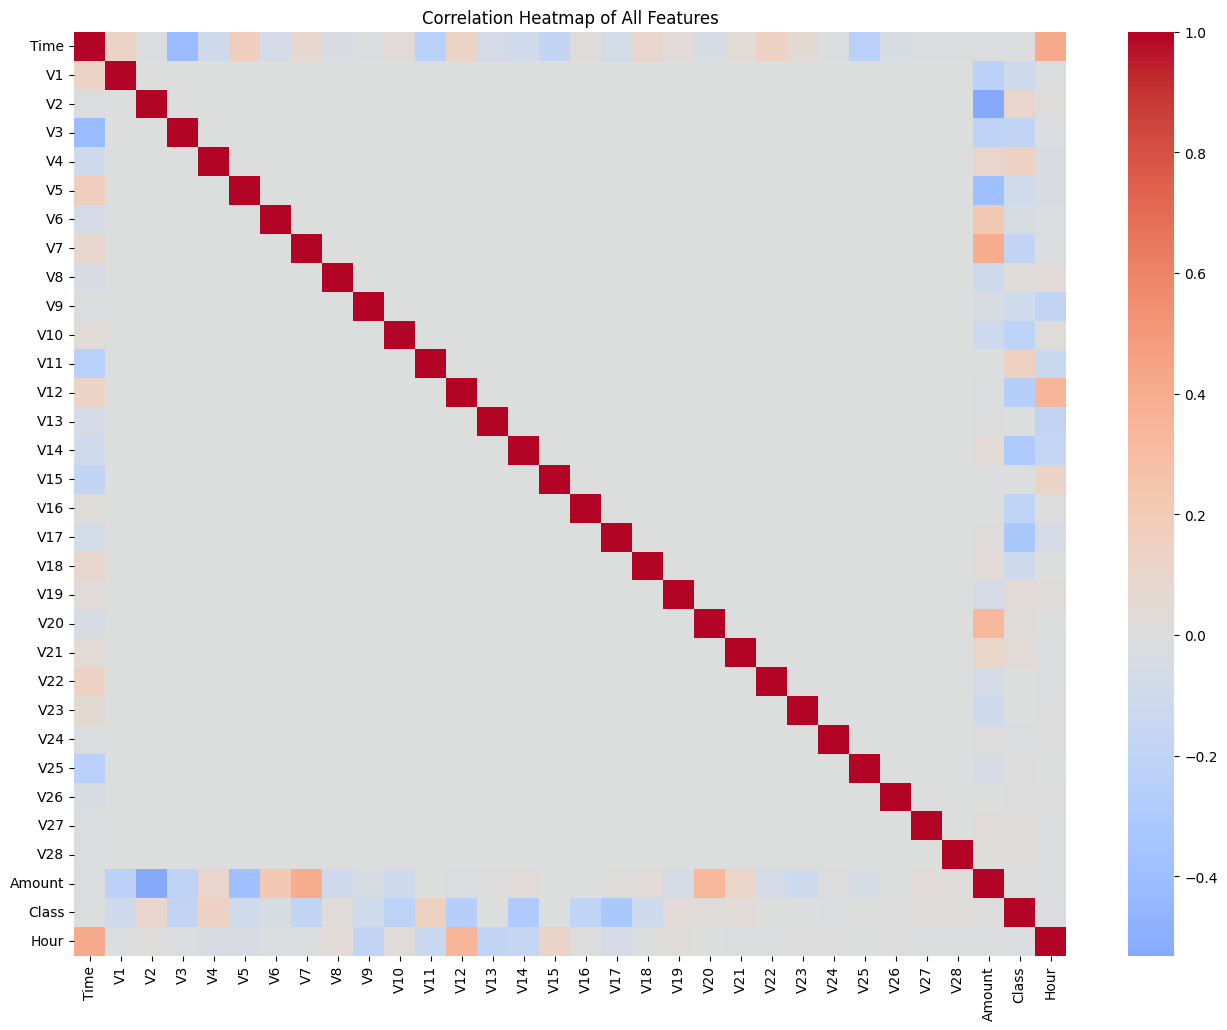

In [18]:
plt.figure(figsize=(16,12))
corr = df.corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Heatmap of All Features")
plt.show()

In [19]:
corr_with_class = df.corr()['Class'].sort_values(ascending=False)
print(corr_with_class)

Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
Hour     -0.017109
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


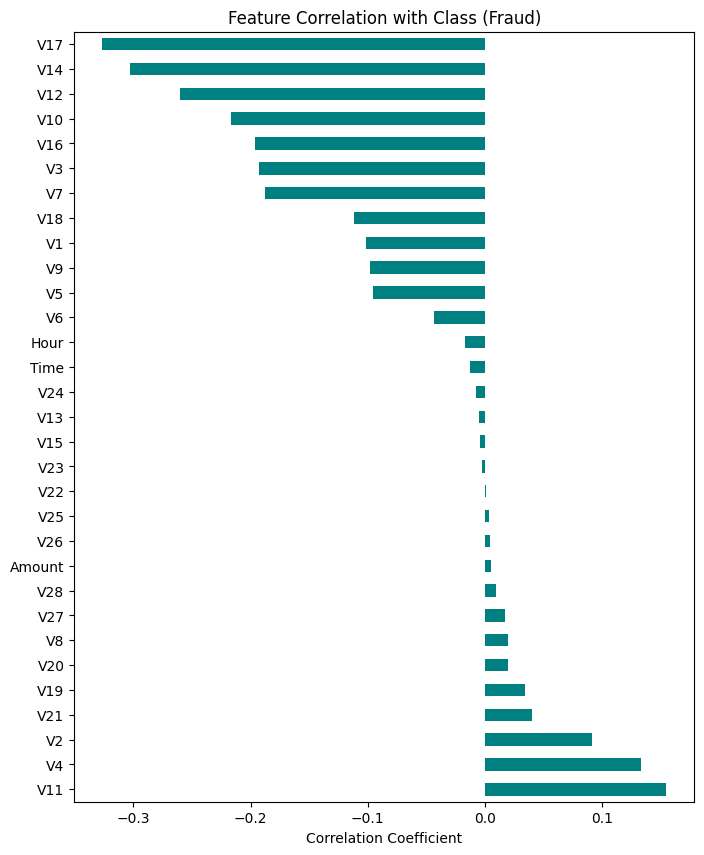

In [20]:
plt.figure(figsize=(8,10))
corr_with_class.drop('Class').plot(kind='barh', color='teal')
plt.title("Feature Correlation with Class (Fraud)")
plt.xlabel("Correlation Coefficient")
plt.show()

#### Correlation Analysis Across Features

1. Orthogonality of PCA Features (V1–V28):
  - The principle component show near-zero correlation among themselves. This confirms that PCA successfully decorrelated these features during dimensionality reduction.

2. Correlations with Amount & Time / Hour:
  - Amount: Show noticeable positive and negative correlation with several PCA components (strong negative with V2 and V5; positive with V7 and V25).
  - Time / Hour: Show mild correlations with specific PCA features (such as V3, V11, V25).

3. Correlations with Target Variable (Class):
  - Most feature show low correlation with class across the full dataset due to extreme class imbalance.
  - Subtle correlations exist with features like V11, V4 (positive) and V12, V14, V17 (negative), suggesting these features carry predictive signals for fraud detection.

#### Distribution of top correlated features (fraud vs legit)

Top rated features: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


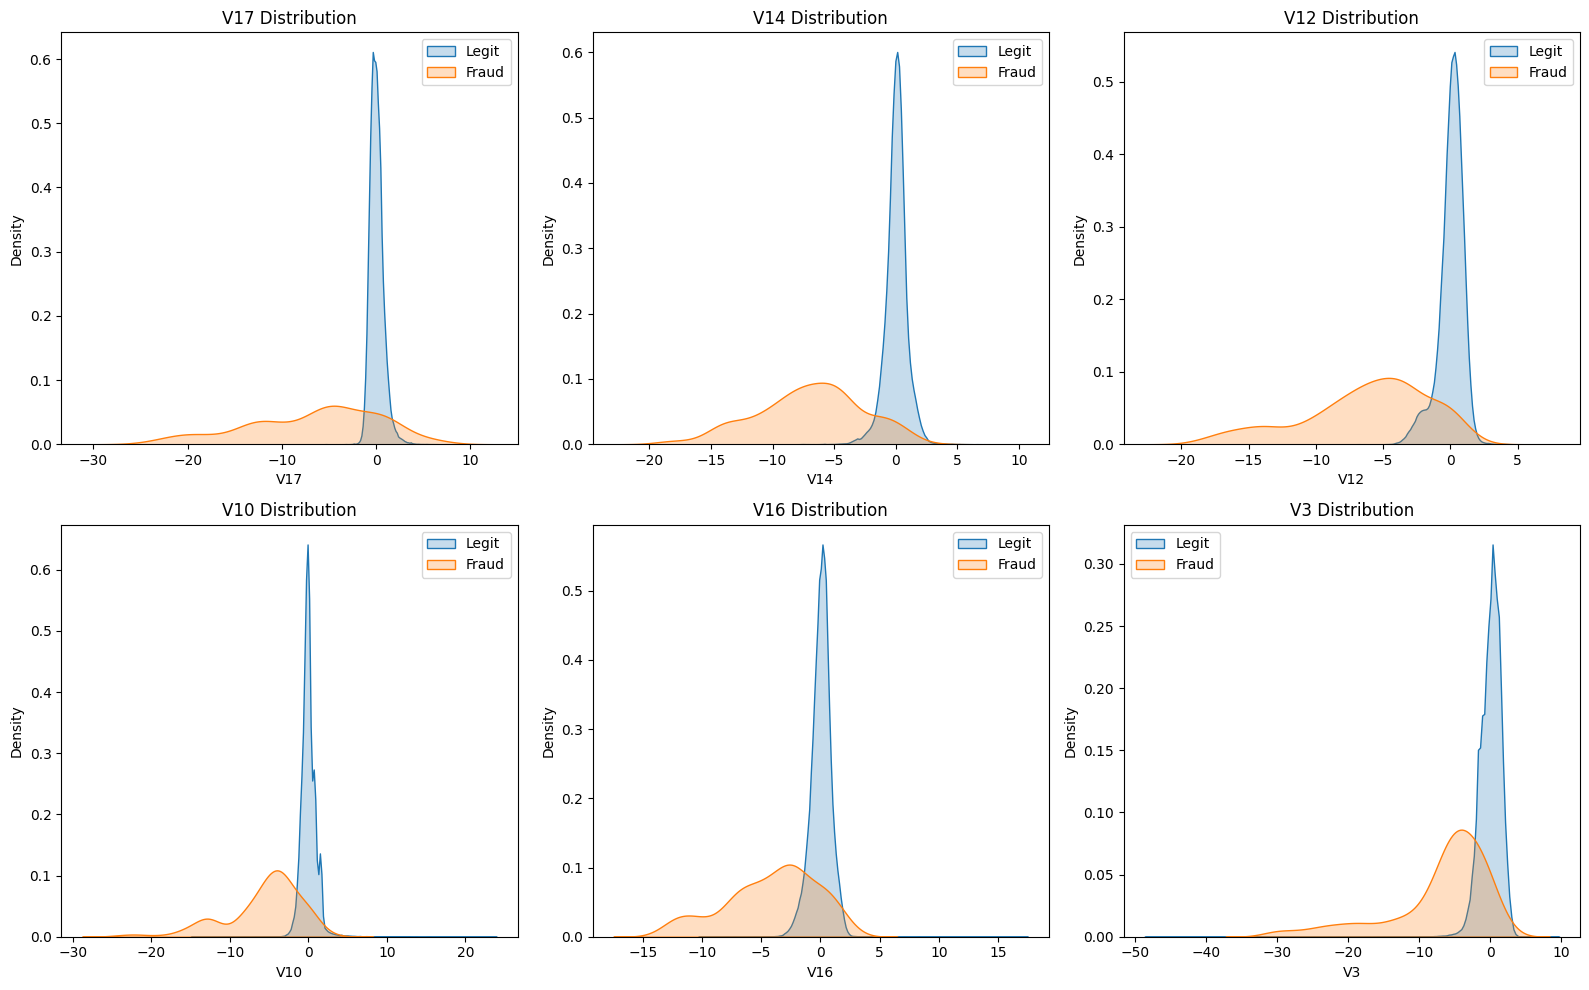

In [24]:
top_features = corr_with_class.drop('Class').abs().sort_values(ascending=False).head(6).index.to_list()
print(f'Top rated features:', top_features)

fig, axes = plt.subplots(2, 3, figsize=(16,10))
axes = axes.flatten()

for i, col in enumerate(top_features):
    sns.kdeplot(data=df[df['Class'] == 0], x=col, ax=axes[i], label='Legit', fill=True)
    sns.kdeplot(data=df[df['Class'] == 1], x=col, ax=axes[i], label='Fraud', fill=True)
    axes[i].set_title(f'{col} Distribution')
    axes[i].legend()

plt.tight_layout()
plt.show()

#### Distribution Analysis of Top Negatively Correlated Features

1. Clear Class Separation:
  - For Legit transaction, values are tightly concentrated around 0 with a high peak density.
  - For Fraud transaction, the distribution shift significantly toward negative values (spanning down to -25 for V17, -20 for V14, and -50 for V3) with a wider, flatter dispersion.

2. Strong Predictive Signal:
  - Features like V17, V14, and V12 demonstrate the most distinct separation between classes, indicating they serve as critical features for distinguishing fraud from non-fraud cases.

3. Presence of Extreme Outliers:
  - The long left-hand tails in the fraud distributions highlight extreme negative outliers within these features.

#### Outlier detection (boxplots on top features)

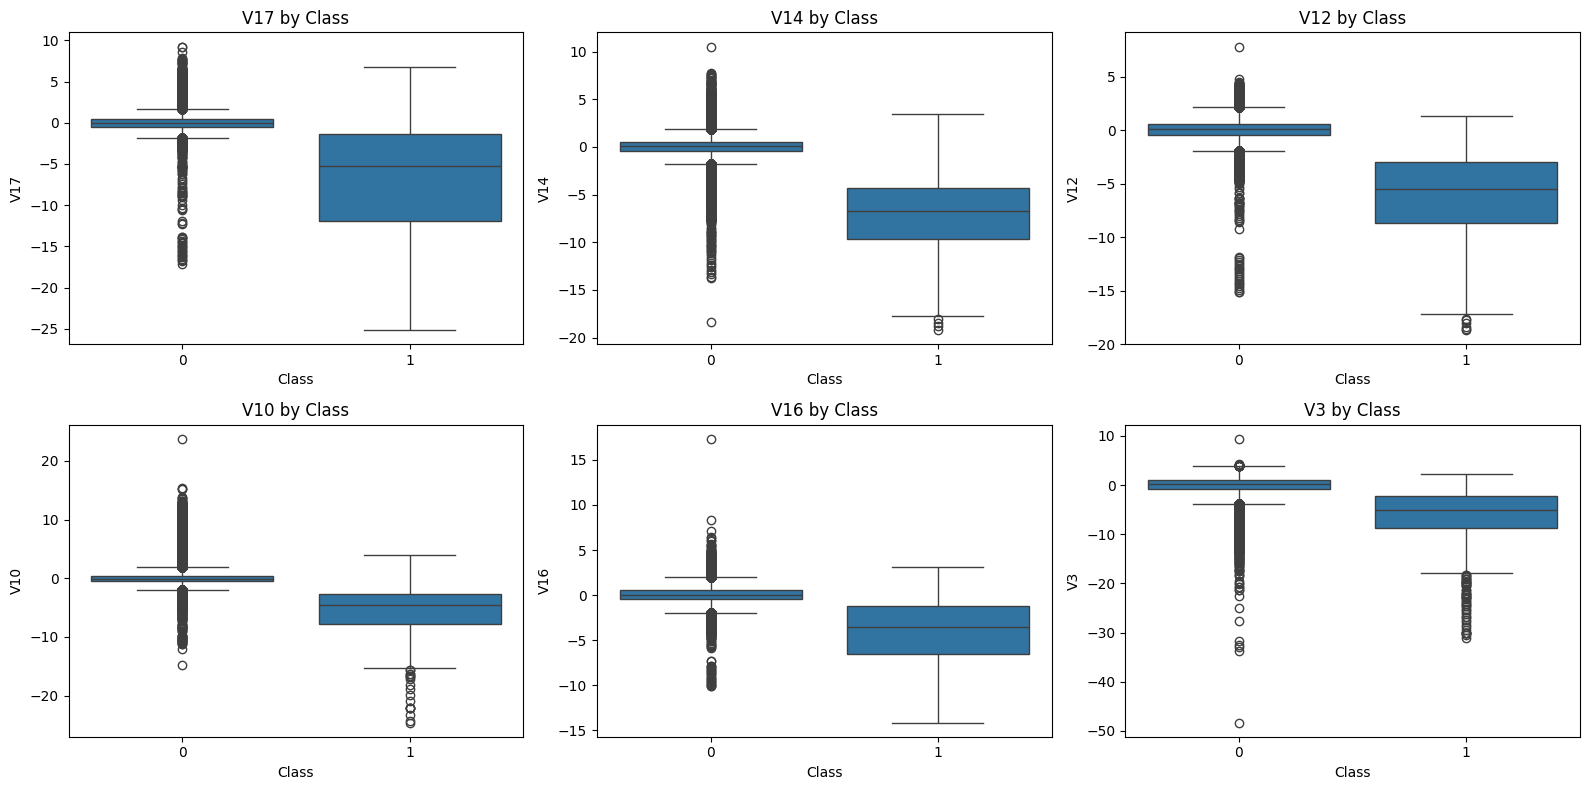

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(top_features):
    sns.boxplot(data=df, x='Class', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Class')

plt.tight_layout()
plt.show()

#### Box Plot Analysis of Features Across Classes

1. Distribution Shift & Variance:
  - Class 0 (Non-Fraud): Shows an extremely narrow Interquartile Range (IQR) centered tightly around $0$. However, due to the massive sample size, it contains large amounts of outliers beyond the edge.
  - Class 1 (Fraud): Shows significantly lower medians and much wider IQRs, confirming that fraudulent transactions consistently push feature values into lower negative ranges.

2. Feature Separation Highlights:
  - V14 & V17: Display almost non-overlapping IQRs between classes, making them exceptional linear separators for detecting fraud.
  - V10, V12, V16, and V3: Also shows high separation, with median values for Class 1 sitting well below the lower whisker of Class 0.

3. Outlier Profiles:
  - Extreme negative values (e.g., V17 below $-20$, V14 below $-15$, and V3 below $-30$) are almost exclusively associated with fraudulent transactions.

#### Skewness check (relevant for scaling decisions later)

In [27]:
skew_vals = df.drop(columns=['Class']).skew().sort_values(ascending=False)
print(skew_vals)

Amount    16.977724
V28       11.192091
V21        3.592991
V7         2.553907
V6         1.826581
V10        1.187141
V4         0.676292
V26        0.576693
V9         0.554680
V11        0.356506
V19        0.109192
V13        0.065233
Time      -0.035568
V22       -0.213258
V18       -0.259880
V15       -0.308423
V25       -0.415793
Hour      -0.490470
V24       -0.552499
V16       -1.100966
V27       -1.170209
V14       -1.995176
V20       -2.037155
V3        -2.240155
V12       -2.278401
V5        -2.425901
V1        -3.280667
V17       -3.844914
V2        -4.624866
V23       -5.875140
V8        -8.521944
dtype: float64


Highly skewed variables such as Amount may benefit from log transformation or robust scaling depending on the chosen machine learning algorithm.

#### Duplicate check (often skipped but important)

In [28]:
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 1081


Duplicate transactions can bias model training and evaluation. They should be investigated before preprocessing.

### EDA Summary

- The dataset is highly imbalanced (~0.17% fraud).
- No missing values were detected.
- Several PCA features exhibit strong relationships with the target class.
- Fraudulent transactions show distinct distributions for several features.
- Transaction amounts are highly skewed.
- Duplicate records exist and should be handled before model training.
- These findings guide the preprocessing stage, including duplicate removal, feature scaling, and imbalance handling using SMOTE.

**Next step:** Feature Engineering — including scaling `Amount`/`Time`, potentially dropping low-correlation features, and preparing the dataset for handling class imbalance.